In [1]:
# Step 1 - Open Colab and load the penguins

In [2]:
import pandas as pd


In [3]:
df=pd.read_csv("Downloads/penguins.csv")

In [4]:
# Step 2 - Establish ground truth by hand, no AI

In [5]:
df.shape

(344, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


In [7]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [8]:
print(df.isnull().sum())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [9]:
print(df["species"].value_counts())

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [10]:
print(df.groupby("species")["flipper_length_mm"].mean())

species
Adelie       189.953642
Chinstrap    195.823529
Gentoo       217.186992
Name: flipper_length_mm, dtype: float64


In [11]:
# Step 3 - Prompt the AI (and log it)

Prompt Log

You are helping with exploratory data analysis.
My CSV has columns: species (object), island (object), bill_length_mm (float64), bill_depth_mm (float64), flipper_length_mm (float64), body_mass_g (float64), sex (object), year (int64).
Write Python using pandas and seaborn to:
* (1) summarize missing data,
* (2) compare flipper_length_mm across species,
* (3) produce one labeled chart.

Explain each step in comments.

In [12]:
# Step 4 - Run the AI’s code

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

Missing Data Summary:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Flipper Length Comparison by Species:


,count,mean,median,std
species,,,,
Adelie,151,189.953642,190.0,6.539457
Chinstrap,68,195.823529,196.0,7.131894
Gentoo,123,217.186992,216.0,6.484976


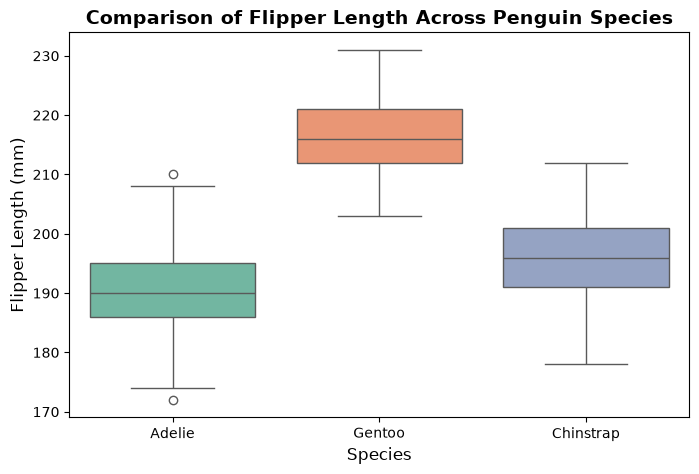

In [14]:
# (1) Summarize missing data
print("Missing Data Summary:")
print(df.isnull().sum())

# (2) Compare flipper_length_mm across species
species_flipper_summary = df.groupby("species")["flipper_length_mm"].agg(
    ["count", "mean", "median", "std"]
)
print("\nFlipper Length Comparison by Species:")
display(species_flipper_summary)

# (3) Produce one labeled chart
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="species",
    y="flipper_length_mm",
    hue="species",
    palette="Set2",
    legend=False,
)
plt.title(
    "Comparison of Flipper Length Across Penguin Species",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Species", fontsize=12)
plt.ylabel("Flipper Length (mm)", fontsize=12)
plt.show()

In [15]:
# Step 5 -  verification check

In [16]:
ai_comparison_check = df.groupby("species")["flipper_length_mm"].mean()
print("Verification Check - Mean Flipper Length:")
print(ai_comparison_check)

Verification Check - Mean Flipper Length:
species
Adelie       189.953642
Chinstrap    195.823529
Gentoo       217.186992
Name: flipper_length_mm, dtype: float64


My hand-computed groupby mean flipper lengths (Adelie: 189.95, Chinstrap: 195.82, Gentoo: 217.19) perfectly match the values produced by the AI's script. It is also verified by the df.describe section when I was checking the data. Both methods look to drop the 2 missing rows without causing discrepancies.

In [17]:
# Step 6: One follow-up, one judgment

In [18]:
# Follow-up - looking at body mass across the species and sex with a box plot

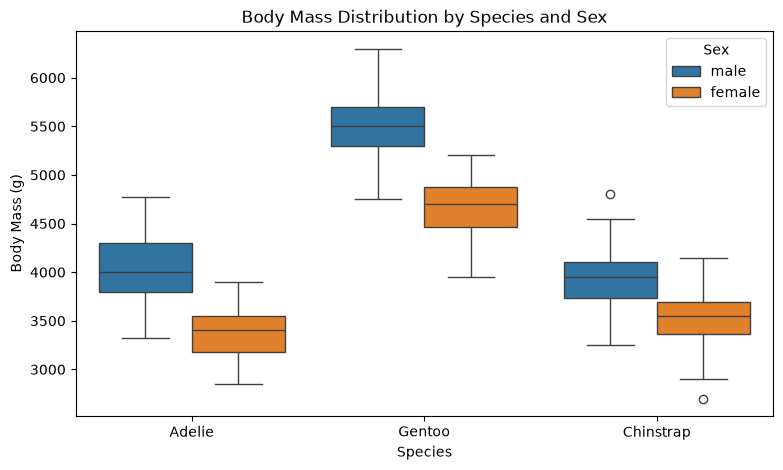

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df, x="species", y="body_mass_g", hue="sex")
plt.title("Body Mass Distribution by Species and Sex")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")
plt.legend(title="Sex")
plt.show()

In [20]:
# Step 7: Your original insight, no AI

Across all species, the male penguins are heavier than females, showing a clear weight gap between the sexes. Additionally, Gentoo penguins are much heavier than both Adelie and Chinstraps penguins that even female Gentoos weigh more than the males of the other two species.

In [21]:
df.groupby(["species", "sex"])["body_mass_g"].mean()

species    sex   
Adelie     female    3368.835616
           male      4043.493151
Chinstrap  female    3527.205882
           male      3938.970588
Gentoo     female    4679.741379
           male      5484.836066
Name: body_mass_g, dtype: float64

In [22]:
# Step 8: Privacy reflection (markdown cell)

One dataset from my own work or life that I must never paste into a public AI tool is a database containing sensitive employee information and records. Doing so would violate company I.T. policies and privacy laws. Instead, I would try to group the data by department brackets, or process that would make it more generalized without the senitive information to be used for AI analysis.